# Variational Autoencoder (VAE) — PyTorch

**Workflow:**
1. Train the VAE on **both** images simultaneously
2. Encode both images into latent vectors **z₁** and **z₂**
3. Decode the **midpoint** `0.5·z₁ + 0.5·z₂` → a blend of both images
4. Visualise the full interpolation strip + loss curve + random samples

---

## 1 · Imports & Setup

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

print(f"PyTorch : {torch.__version__}")

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print(f"Device  : {DEVICE}")

PyTorch : 2.12.0
Device  : mps


## 2 · Configuration

In [2]:
IMG_SIZE   = 64    # all images resized to this square
LATENT_DIM = 128   # latent vector size
EPOCHS     = 500   # epochs — both images trained jointly
LR         = 1e-3  # Adam learning rate
KL_WEIGHT  = 0.5   # beta weight on KL divergence
N_STEPS    = 9     # interpolation steps between the two images

## 3 · Image Utilities

In [3]:
to_tensor = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

def load_image(path: str) -> torch.Tensor:
    return to_tensor(Image.open(path).convert("RGB")).unsqueeze(0).to(DEVICE)

def to_numpy(t: torch.Tensor):
    return t.squeeze(0).permute(1, 2, 0).clamp(0, 1).cpu().detach().numpy()

## 4 · VAE Model

In [4]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        ch = [3, 32, 64, 128, 256]

        enc = []
        for i in range(len(ch) - 1):
            enc += [nn.Conv2d(ch[i], ch[i+1], 4, 2, 1), nn.ReLU()]
        self.encoder = nn.Sequential(*enc)

        flat = ch[-1] * (IMG_SIZE // 2**4) ** 2
        self.fc_mu  = nn.Linear(flat, LATENT_DIM)
        self.fc_var = nn.Linear(flat, LATENT_DIM)

        self.fc_dec       = nn.Linear(LATENT_DIM, flat)
        self.base_ch      = ch[-1]
        self.base_spatial = IMG_SIZE // 2**4

        dec = []
        for i in range(len(ch) - 1, 0, -1):
            out_ch = ch[i-1] if i > 1 else 3
            act    = nn.ReLU() if i > 1 else nn.Sigmoid()
            dec   += [nn.ConvTranspose2d(ch[i], out_ch, 4, 2, 1), act]
        self.decoder = nn.Sequential(*dec)

    def encode(self, x):
        h = self.encoder(x).flatten(1)
        return self.fc_mu(h), self.fc_var(h)

    def reparameterize(self, mu, logvar):
        std = (0.5 * logvar).exp()
        return mu + std * torch.randn_like(std)

    def decode(self, z):
        h = self.fc_dec(z).view(-1, self.base_ch,
                                self.base_spatial, self.base_spatial)
        return self.decoder(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar


model = VAE().to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 2,957,251


## 5 · Loss Function (β-ELBO)

In [5]:
def vae_loss(recon, x, mu, logvar):
    recon_loss = F.mse_loss(recon, x, reduction="sum")
    kld        = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + KL_WEIGHT * kld

## 6 · Load Both Images
Both images are stacked into one batch so the VAE learns a shared latent space covering both.

Batch shape: torch.Size([2, 3, 64, 64])


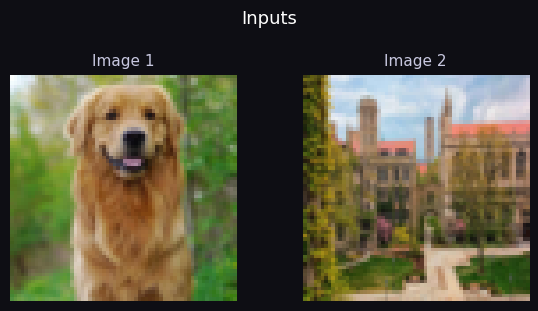

In [6]:
TRAIN_IMAGE = '/Users/macminhanh/Documents/UChicago/Machine Learning II/Assignment 7/train.jpeg'   # <- image 1
TEST_IMAGE  = '/Users/macminhanh/Documents/UChicago/Machine Learning II/Assignment 7/test.jpeg'   # <- image 2

x1 = load_image(TRAIN_IMAGE)
x2 = load_image(TEST_IMAGE)
x_batch = torch.cat([x1, x2], dim=0)   # (2, 3, H, W)
print(f"Batch shape: {x_batch.shape}")

fig, axes = plt.subplots(1, 2, figsize=(6, 3), facecolor="#0e0e14")
for ax, img, title in zip(axes, [x1, x2], ["Image 1", "Image 2"]):
    ax.imshow(to_numpy(img))
    ax.set_title(title, color="#c8c8e0", fontsize=11)
    ax.axis("off")
    ax.set_facecolor("#1a1a2e")
plt.suptitle("Inputs", color="white", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 7 · Train the VAE

In [7]:
opt    = Adam(model.parameters(), lr=LR)
losses = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    opt.zero_grad()
    recon_batch, mu, logvar = model(x_batch)
    loss = vae_loss(recon_batch, x_batch, mu, logvar)
    loss.backward()
    opt.step()
    losses.append(loss.item())
    if epoch % 100 == 0 or epoch == 1:
        print(f"  Epoch {epoch:>4}/{EPOCHS}   Loss: {loss.item():.1f}")

print("\nTraining complete.")

  Epoch    1/500   Loss: 1276.5
  Epoch  100/500   Loss: 181.4
  Epoch  200/500   Loss: 127.6
  Epoch  300/500   Loss: 60.7
  Epoch  400/500   Loss: 44.6
  Epoch  500/500   Loss: 46.9

Training complete.


## 8 · Latent Space Interpolation (Slerp + VAE noise)

**Why linear interpolation (lerp) is uneven:**  
Each image's latent vector has a different magnitude and direction. The geometric midpoint (α=0.5) is not the perceptual midpoint — one image dominates depending on which vector is longer.

**Fix: Spherical linear interpolation (slerp)**  
Slerp travels at constant angular speed along the great-circle arc between μ₁ and μ₂, giving perceptually uniform blending across all α values:

$$z_{\text{slerp}}(\alpha) = \frac{\sin((1-\alpha)\Omega)}{\sin\Omega}\,\hat{\mu}_1 + \frac{\sin(\alpha\,\Omega)}{\sin\Omega}\,\hat{\mu}_2$$

where $\Omega$ is the angle between the two vectors.  
VAE noise is then added: $z = z_{\text{slerp}} + \sigma(\alpha) \cdot \varepsilon$

In [8]:
def slerp(mu1, mu2, alpha):
    """Spherical interpolation between two latent vectors."""
    mu1_n = F.normalize(mu1, dim=-1)
    mu2_n = F.normalize(mu2, dim=-1)
    dot   = (mu1_n * mu2_n).sum(dim=-1, keepdim=True).clamp(-1, 1)
    omega = torch.acos(dot)                        # angle between vectors
    sin_o = torch.sin(omega)
    # Fall back to lerp when vectors are nearly parallel (sin_o ~ 0)
    safe  = sin_o.abs() > 1e-6
    w1    = torch.where(safe, torch.sin((1 - alpha) * omega) / sin_o, 1 - alpha)
    w2    = torch.where(safe, torch.sin(alpha * omega)       / sin_o, alpha)
    # Scale result back to the interpolated magnitude
    mag   = (1 - alpha) * mu1.norm(dim=-1, keepdim=True) + alpha * mu2.norm(dim=-1, keepdim=True)
    return (w1 * mu1_n + w2 * mu2_n) * mag


model.eval()
with torch.no_grad():
    mu1, logvar1 = model.encode(x1)
    mu2, logvar2 = model.encode(x2)

    alphas = torch.linspace(0, 1, N_STEPS, device=DEVICE)
    interp_imgs = []
    for a in alphas:
        # Slerp on the mean vectors — perceptually uniform
        z_slerp  = slerp(mu1, mu2, a)

        # Interpolate uncertainty and add VAE noise
        logvar_a = (1 - a) * logvar1 + a * logvar2
        std      = (0.5 * logvar_a).exp()
        z        = z_slerp + std * torch.randn_like(std)

        interp_imgs.append(model.decode(z))

    blend = interp_imgs[N_STEPS // 2]   # midpoint is now a true 50/50 blend
    print("blend shape:", blend.shape)
    samples = model.decode(torch.randn(16, LATENT_DIM, device=DEVICE))

print(f"Interpolation steps: {N_STEPS}  |  true midpoint at step {N_STEPS // 2 + 1}")
print("Re-run this cell for a different noisy variation of the same blend.")

blend shape: torch.Size([1, 3, 64, 64])
Interpolation steps: 9  |  true midpoint at step 5
Re-run this cell for a different noisy variation of the same blend.


## 9 · Visualization

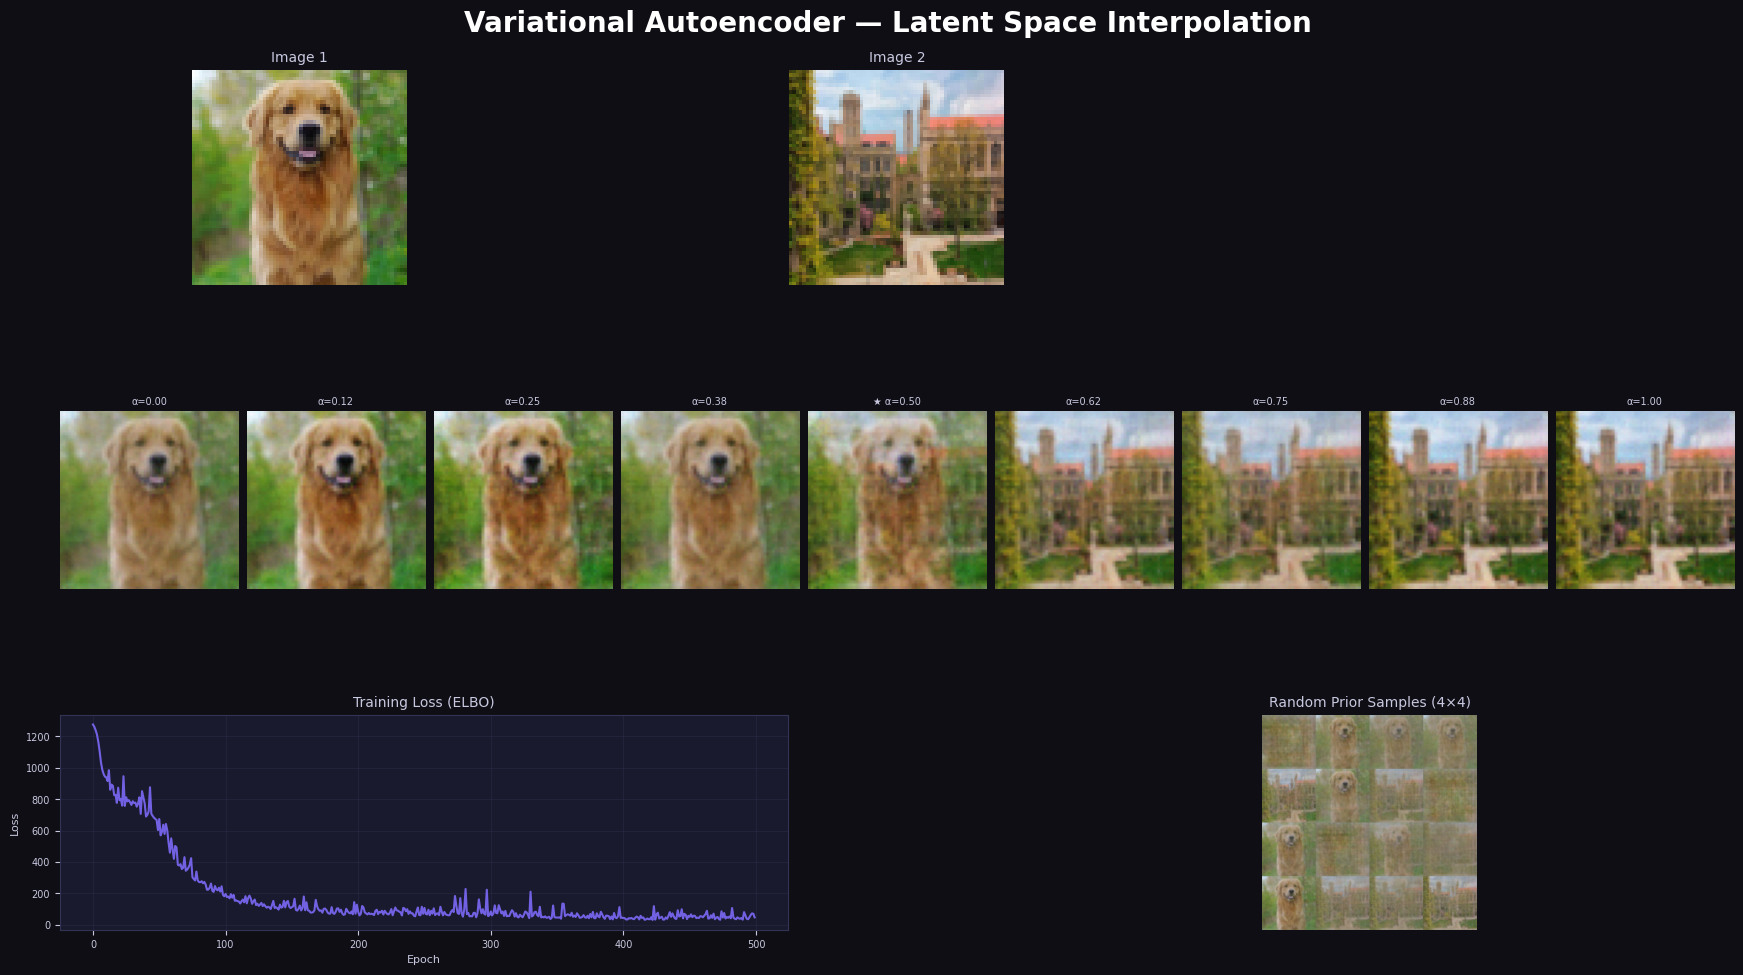

Visualization complete.


In [9]:
fig = plt.figure(figsize=(18, 10), facecolor="#0e0e14")
fig.suptitle("Variational Autoencoder — Latent Space Interpolation",
             fontsize=20, color="white", fontweight="bold", y=0.98)

axes_color = "#1a1a2e"
text_color = "#c8c8e0"
accent     = "#7c6af7"

outer = fig.add_gridspec(3, 1, hspace=0.5,
                         left=0.04, right=0.97, top=0.92, bottom=0.06)

def styled_ax(ax, title):
    ax.set_facecolor(axes_color)
    ax.set_title(title, color=text_color, fontsize=10, pad=6)
    ax.tick_params(colors=text_color, labelsize=7)
    for sp in ax.spines.values(): sp.set_color("#333355")
    return ax

# ── Row 1: Image 1 | blend | Image 2 ─────────────────────────────────────────
row1 = outer[0].subgridspec(1, 3, wspace=0.25)
for ax, img, title in zip(
        [fig.add_subplot(row1[0]), fig.add_subplot(row1[1])],
        [x1, x2],
        ["Image 1", "Image 2"]):
    styled_ax(ax, title).imshow(to_numpy(img))
    ax.axis("off")

# ── Row 2: Full interpolation strip ──────────────────────────────────────────
row2 = outer[1].subgridspec(1, N_STEPS, wspace=0.05)
for i, (img, a) in enumerate(zip(interp_imgs, alphas)):
    ax = fig.add_subplot(row2[i])
    ax.imshow(to_numpy(img))
    ax.axis("off")
    ax.set_facecolor(axes_color)
    label = f"α={a:.2f}"
    if i == N_STEPS // 2:
        label = f"★ {label}"
    ax.set_title(label, color=text_color, fontsize=7, pad=4)

# ── Row 3: Loss curve | random samples ───────────────────────────────────────
row3 = outer[2].subgridspec(1, 2, wspace=0.3)

ax_loss = styled_ax(fig.add_subplot(row3[0]), "Training Loss (ELBO)")
ax_loss.plot(losses, color=accent, linewidth=1.5, alpha=0.9)
ax_loss.set_xlabel("Epoch", color=text_color, fontsize=8)
ax_loss.set_ylabel("Loss",  color=text_color, fontsize=8)
ax_loss.grid(color="#333355", alpha=0.5, linewidth=0.5)

ax_samp = styled_ax(fig.add_subplot(row3[1]), "Random Prior Samples (4×4)")
ax_samp.axis("off")
rows, cols = 4, 4
s_np     = [to_numpy(samples[i]) for i in range(rows * cols)]
grid_img = np.concatenate(
    [np.concatenate(s_np[r*cols:(r+1)*cols], axis=1) for r in range(rows)], axis=0)
ax_samp.imshow(grid_img)

plt.show()
print("Visualization complete.")

#### **Write-ups**
The visualization shows a 9-step interpolation strip going from the dog (α=0.00) to the building (α=1.00), with a true 50/50 blend at the midpoint (α=0.50).

Unlike Part A, where the VAE was only trained on the dog image and produced a dog-like reconstruction regardless of the test input, Part B trains the VAE on both images simultaneously. This forces the model to learn a shared latent space that encodes the visual features of both images.

Instead of a simple reconstruction, Part B produces a latent space interpolation, a smooth transition strip of 9 images blending from the dog (α=0.00) to the UChicago building (α=1.00). At the midpoint (α=0.50), the output is a genuine visual blend of both images.

Because both images were included in training, the encoder learned to place them at two distinct but related points in the latent space. By using spherical linear interpolation (slerp) between the two encoded latent vectors (μ₁ and μ₂), the decoder can generate meaningful intermediate images that gradually transition between the two. This is only possible because the model has seen both images. It now understands both visual distributions and can navigate between them in latent space.

In summary, Part A shows the VAE's limitation when trained on one image; Part B shows its generative power when trained on multiple images, enabling smooth latent space traversal between them.

Loss started at 1276 and dropped to 47 over 500 epochs. This is higher starting loss than Part A because it's now learning two images at once.

Random prior samples still lean dog-heavy, which is normal since both share similar color distributions (warm tones, green backgrounds)